# 35 — R2 Part C: give the posterior the measured inlet temperatures (System I)

**Why.** Notebook 34: the production posterior assumes the nominal inlet and is confidently wrong
when it is not — a 0.5 K error in the coolant inlet temperature Tci biases β by 7–13 posterior sds,
because the coolant warms by only ≈ 3 K in the jacket. Treating the inlet as unknown (nb34 Part B)
restores calibration but costs 5× in β precision. Real plants measure Tci and Ti, and their coolant
supply drifts by several K over a day or a season, so a fixed-inlet model would fail in practice
anyway. Here the posterior **receives the measured inlet temperatures**, and the question becomes:
**how accurate must those measurements be?** In the storyline: the fourth silent-failure source and
its remedy — a concrete instrument requirement for the practitioner checklist.

**Design** (N3 sensors, P2 protocol)
* Plant inlet varies per window: Ti, Tci ~ U(295, 299) K; Ci ± 1% (unmeasured).
* Inlet sensors: measured = true + calibration offset ε·N(0,1) (fixed per window) + window-mean
  white noise (0.2 K RTD averaged over 60 min).
* Features (34-D): the 29 summaries, the three plug-in estimators recomputed with the **measured**
  Ti and Tci, and the two measured temperatures.
* Variants, 3-seed ensembles at 40k, same draws and seeds: **oracle** (inlet known exactly),
  **ε = 0.05 K** (calibrated / matched pair), **ε = 0.1 K** (class-AA RTD), **ε = 0.2 K** (class-A RTD),
  **marginal** (no inlet measurement, inlet unknown). Reference: the N3 production posterior
  (assumes the nominal inlet).
* Tests: SBC set (1000 prior draws, inlet from the training distribution) and the scenario grid
  Sc1–Sc5 × 50 at fixed true inlets (nominal; Tci and Ti each ±0.5, ±1, ±2 K).

## Decision rule — fixed before running
A variant is **deployable** if it is calibrated on the SBC set (interior marginal KS p ≥ 0.01 for
α and β, TARP KS p ≥ 0.01) and, for every scenario Sc1–Sc4 and every inlet condition within ±2 K,
β 90% coverage at the truth ≥ 0.80 and class accuracy ≥ the oracle's − 0.10.
**Instrument requirement** = the largest deployable ε among {0.05, 0.1, 0.2} K.
**Production recommendation** (a user decision; the notebook changes nothing): ε = 0.1 K if
deployable, else ε = 0.05 K, else the marginal posterior with its precision cost.

**Running.** ≈ 1.5–2.5 h (120k simulations, 15 trainings, evaluation). Re-running resumes.


In [1]:
import json, os, sys, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
NB_DIR = Path.cwd().resolve()
assert NB_DIR.name == "system_I" and NB_DIR.parent.name == "notebooks", f"run from notebooks/system_I (cwd {NB_DIR})"
ROOT = NB_DIR.parent.parent
for p in (ROOT / "src", ROOT / "scripts"):
    sys.path.insert(0, str(p))
os.environ["CSTR_SENSOR_MODEL"] = "N3"
import importlib, system_I_config, ws_protocols, ws_eval, ws_metrics, ws_inlet, nb29_ws_study, nb31_budget_convergence, nb35_measured_inlet
for _m in (system_I_config, ws_protocols, ws_eval, ws_metrics, ws_inlet, nb29_ws_study, nb31_budget_convergence, nb35_measured_inlet):
    importlib.reload(_m)
M = nb35_measured_inlet
assert M.SENSOR == "N3", M.SENSOR
R, FIGS = ROOT / "results", ROOT / "figures"
THREADS = 4
T0 = time.time()
print("sensor", M.SENSOR, "| protocol", M.PROTOCOL, "| outputs", M.TAG, "| variants", list(M.VARIANTS))

sensor N3 | protocol P2 | outputs 35_N3 | variants ['oracle', 'eps0.05', 'eps0.1', 'eps0.2', 'marginal']


## 1. Simulate (training bank with varying inlet; test sets) and train the five variants

In [2]:
M.stage_bank()
M.stage_test()
M.stage_train(THREADS)
print(f"{(time.time() - T0) / 60:.1f} min")

0.0 min


## 2. Evaluate (the five variants and the production posterior)

In [3]:
M.stage_eval()
sbc = pd.read_csv(R / f"{M.TAG}_sbc.csv")
display(sbc[["variant", "eps", "ks_p_a_interior", "ks_p_b_interior", "tarp_ks_p", "cov90_a", "cov90_b",
             "sd_a_median", "sd_b_median", "rmse_norm", "leak_mean"]].round(4))
m = pd.read_csv(R / f"{M.TAG}_metrics.csv"); m["short"] = m.scenario.str.split("_").str[0]
order = list(M.CONDITIONS)
for k in ("bias_b", "z_bias_b", "cov90_truth_b", "sd_b", "class_acc"):
    print(k)
    display(m.pivot_table(index=["variant", "condition"], columns="short", values=k).reindex(order, level=1).round(3))

oracle evaluated


eps0.05 evaluated


eps0.1 evaluated


eps0.2 evaluated


marginal evaluated


production evaluated


... (7 outputs left out)

sd_b


short                   Sc1    Sc2    Sc3    Sc4    Sc5
variant    condition                                   
eps0.05    nominal    0.025  0.034  0.024  0.029  0.044
           Tci-0.5    0.024  0.029  0.024  0.025  0.043
           Ti-0.5     0.025  0.024  0.026  0.022  0.044
           Tci+0.5    0.026  0.042  0.025  0.036  0.045
           Ti+0.5     0.031  0.049  0.027  0.048  0.043
...                     ...    ...    ...    ...    ...
production Ti+1.0     0.023  0.026  0.020  0.026  0.012
           Tci-2.0    0.044  0.017  0.041  0.021  0.000
           Ti-2.0     0.028  0.028  0.028  0.029  0.051
           Tci+2.0    0.001  0.001  0.000  0.000  0.001
           Ti+2.0     0.031  0.026  0.030  0.026  0.008

[78 rows x 5 columns]

class_acc


short                  Sc1   Sc2   Sc3   Sc4   Sc5
variant    condition                              
eps0.05    nominal    1.00  0.92  1.00  0.80  1.00
           Tci-0.5    1.00  0.94  1.00  0.78  1.00
           Ti-0.5     1.00  1.00  1.00  0.78  1.00
           Tci+0.5    1.00  0.90  1.00  0.78  1.00
           Ti+0.5     1.00  0.92  1.00  0.76  1.00
...                    ...   ...   ...   ...   ...
production Ti+1.0     0.04  1.00  0.38  0.74  1.00
           Tci-2.0    0.00  0.46  0.00  1.00  0.00
           Ti-2.0     0.80  0.00  1.00  0.00  0.76
           Tci+2.0    1.00  0.12  1.00  0.00  0.02
           Ti+2.0     0.00  1.00  0.00  0.60  1.00

[78 rows x 5 columns]

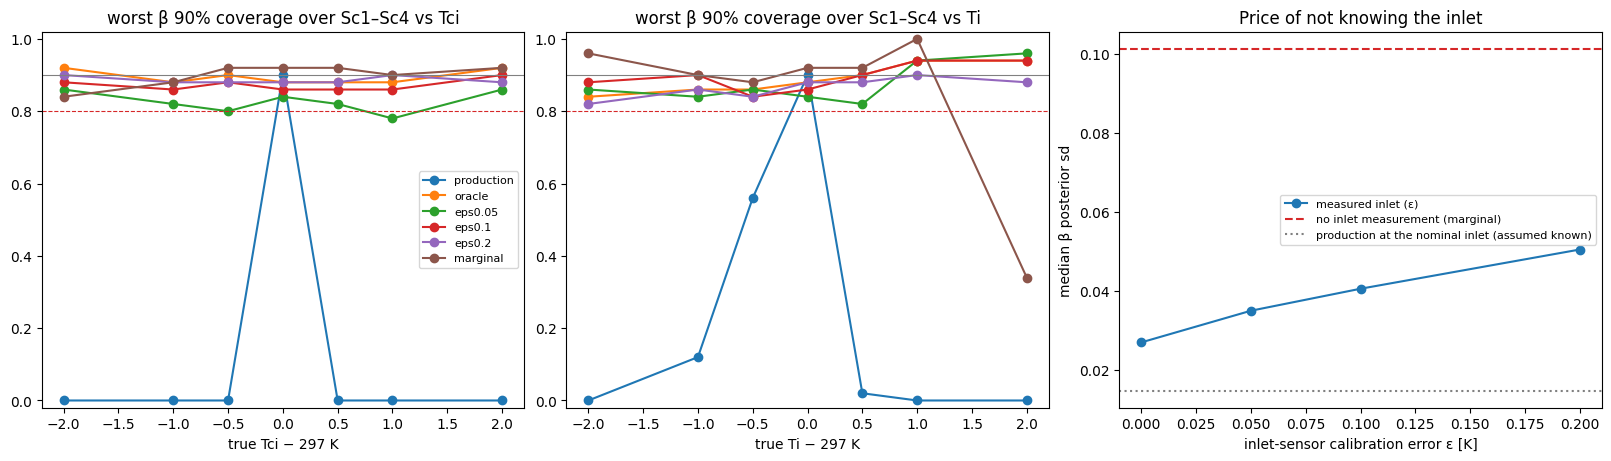

In [4]:
vs = ["production"] + list(M.VARIANTS)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for ax, fac in zip(axes[:2], ("Tci", "Ti")):
    conds = [f"{fac}-2.0", f"{fac}-1.0", f"{fac}-0.5", "nominal", f"{fac}+0.5", f"{fac}+1.0", f"{fac}+2.0"]
    xs = [-2, -1, -.5, 0, .5, 1, 2]
    for v in vs:
        d = m[(m.variant == v) & m.short.isin(M.GATED)].groupby("condition").cov90_truth_b.min().reindex(conds)
        ax.plot(xs, d.values, "o-", label=v)
    ax.axhline(0.8, color="C3", ls="--", lw=0.8); ax.axhline(0.9, color="grey", lw=0.8)
    ax.set_ylim(-0.02, 1.02); ax.set_xlabel(f"true {fac} − 297 K"); ax.set_title(f"worst β 90% coverage over Sc1–Sc4 vs {fac}")
axes[0].legend(fontsize=8)
ax = axes[2]
s = sbc.set_index("variant")
eps_v = [v for v in M.VARIANTS if M.VARIANTS[v] is not None]
ax.plot([M.VARIANTS[v] for v in eps_v], [s.loc[v, "sd_b_median"] for v in eps_v], "o-", label="measured inlet (ε)")
ax.axhline(s.loc["marginal", "sd_b_median"], color="C3", ls="--", label="no inlet measurement (marginal)")
nom = m[(m.variant == "production") & (m.condition == "nominal") & m.short.isin(M.GATED)].sd_b.median()
ax.axhline(nom, color="grey", ls=":", label="production at the nominal inlet (assumed known)")
ax.set_xlabel("inlet-sensor calibration error ε [K]"); ax.set_ylabel("median β posterior sd")
ax.set_title("Price of not knowing the inlet"); ax.legend(fontsize=8)
fig.savefig(FIGS / f"{M.TAG}_coverage_and_precision.png", dpi=150); plt.show()

## 3. Decision (pre-set rule)

In [5]:
dec = M.stage_decide()
for v, o in dec["variants"].items():
    if o["violations"]:
        print(v); display(pd.DataFrame(o["violations"]).round(3).head(12))
print(f"notebook wall time {(time.time() - T0) / 60:.1f} min")

         calibrated n_violations deployable sd_b_median_sbc
oracle        False            0      False        0.027005
eps0.05        True            1      False         0.03502
eps0.1         True            1      False        0.040587
eps0.2         True           17      False        0.050511
marginal       True           29      False        0.101333
instrument requirement: None | recommended for production (user decision): None
eps0.05


,condition,scenario,cov90_b,class_acc,oracle_acc,z_bias_b
0,Tci+1.0,Sc1,0.78,1.0,1.0,-0.206


eps0.1


,condition,scenario,cov90_b,class_acc,oracle_acc,z_bias_b
0,Tci+0.5,Sc2,0.98,0.86,1.0,0.046


eps0.2


,condition,scenario,cov90_b,class_acc,oracle_acc,z_bias_b
0,nominal,Sc2,0.96,0.74,1.00,0.165
1,nominal,Sc4,0.96,0.56,0.76,0.128
2,Tci-0.5,Sc2,0.88,0.70,1.00,0.223
3,Tci-0.5,Sc4,0.96,0.58,0.80,0.184
4,Ti-0.5,Sc2,0.88,0.84,1.00,0.058
5,Ti-0.5,Sc4,0.92,0.66,0.78,0.142
6,Tci+0.5,Sc2,0.96,0.72,1.00,0.096
7,Tci+0.5,Sc4,0.96,0.56,0.76,0.095
8,Tci-1.0,Sc2,0.90,0.74,1.00,0.196
9,Tci-1.0,Sc4,0.96,0.64,0.78,0.231


marginal


,condition,scenario,cov90_b,class_acc,oracle_acc,z_bias_b
0,nominal,Sc2,0.92,0.30,1.00,0.545
1,nominal,Sc4,0.96,0.40,0.76,0.422
2,Tci-0.5,Sc2,0.92,0.28,1.00,0.725
3,Tci-0.5,Sc4,0.92,0.40,0.80,0.447
4,Ti-0.5,Sc2,0.88,0.54,1.00,0.329
5,Ti-0.5,Sc4,0.92,0.54,0.78,0.302
6,Tci+0.5,Sc2,0.98,0.42,1.00,0.329
7,Tci+0.5,Sc3,0.92,0.84,1.00,0.173
8,Tci+0.5,Sc4,1.00,0.26,0.76,0.417
9,Ti+0.5,Sc3,0.92,0.88,1.00,0.175


notebook wall time 0.0 min


## 4. Interpretation (N3 + P2; written 2026-11-09, updated after the user's decisions the same day)

**Result.** Giving the posterior the **measured** inlet temperatures removes the silent failure of notebook 34: at every inlet condition within ±2 K the measured-inlet posteriors keep pooled β coverage at 0.90–0.95 and mean |bias| below 0.02, where the production posterior (nominal inlet assumed) has coverage 0.00–0.47 (0.00 for every coolant-temperature error and for every ±2 K error) and a β bias of 0.035–0.31 (about 10 posterior sd for Tci ±0.5 K). The price is β precision, and the instrument requirement the data support is a **coolant inlet temperature measured to about 0.1 K or better**. The rule as fixed before the run found **no deployable variant** and its fallback clause recommended the marginal posterior, the worst variant; the user amended that clause after the results (**v1.1**, below): a recommended posterior must itself be deployable, so **nothing is recommended at 40k**, ε = 0.05 and 0.1 K miss one cell each, and the user adopted the ε = 0.1 K design for production, to be trained and checked with the full budget study in notebook 36. This is the remedy part of the storyline's inlet-condition item (the posterior is reliable if the inlet it assumes is the inlet it gets) and it gives the checklist its instrument requirement.

**1. Remedy: the nb34 silent failure is removed.** Pooled over Sc1–Sc4, β 90% coverage / mean |β bias| / class accuracy at the same true inlets:

| inlet condition | production | oracle | ε 0.05 | ε 0.1 | ε 0.2 |
|---|---|---|---|---|---|
| Tci ±0.5 K | 0.00 / 0.183 / 0.54 | 0.92 / 0.002 / 0.95 | 0.90 / 0.002 / 0.93 | 0.94 / 0.004 / 0.90 | 0.92 / 0.008 / 0.81 |
| Ti ±0.5 K | 0.47 / 0.035 / 0.95 | 0.93 / 0.003 / 0.94 | 0.90 / 0.003 / 0.93 | 0.93 / 0.004 / 0.93 | 0.91 / 0.006 / 0.88 |
| Tci ±2 K | 0.00 / 0.311 / 0.45 | 0.95 / 0.004 / 0.93 | 0.91 / 0.003 / 0.93 | 0.93 / 0.006 / 0.92 | 0.93 / 0.007 / 0.89 |
| Ti ±2 K | 0.00 / 0.204 / 0.43 | 0.92 / 0.005 / 0.91 | 0.93 / 0.006 / 0.89 | 0.94 / 0.006 / 0.90 | 0.91 / 0.020 / 0.88 |

Over all 13 conditions the measured-inlet posteriors have mean coverage 0.91–0.93 (lowest cell 0.78–0.84) and mean |bias|/sd 0.10–0.16, the production posterior 0.17 coverage. The marginal posterior (no measurement) also keeps coverage (0.91 overall, 0.68 at Ti ±2 K) at a large precision cost.

**2. Instrument requirement and β precision (nominal inlet, pooled Sc1–Sc4; SBC median in brackets).** β sd: production 0.015 (valid only if the inlet is the nominal one), oracle (inlet known exactly) 0.017 [0.027], **ε = 0.05 K 0.028 [0.035], ε = 0.1 K 0.039 [0.041], ε = 0.2 K 0.055 [0.051]**, marginal 0.111 [0.101]; α sd is 0.043–0.045 for all (the inlet temperatures do not touch α). Class accuracy at the nominal inlet: oracle 0.94, ε 0.05 0.93, ε 0.1 0.905, ε 0.2 0.82, marginal 0.655. A 0.1 K measurement costs 2.3 times the oracle's β sd and is 2.8 times more precise than not measuring; 0.05 K costs 1.6 times the oracle; 0.2 K gives a β sd (0.055) as large as the distance of Sc2 and Sc4 (β = 0.85) to the class threshold (0.05), and accuracy falls to 0.82 there. *Checklist item:* **measure the coolant inlet temperature (and the feed temperature) to ≤ 0.1 K, with a calibrated RTD or a matched pair with the jacket-outlet sensor, or accept a β sd of about 0.1 (marginal) with class accuracy 0.65; do not assume the nominal inlet.**

**3. The rule's recommendation, the amendment v1.1 and the decision.** Per variant (violations of the deployability criteria over the 52 cells Sc1–Sc4 × 13 conditions; 50 windows per cell): oracle 0 but **not calibrated** (TARP KS p 0.0004, deviation 0.062; interior KS p 0.014 and 0.41); ε = 0.05: calibrated (interior KS p 0.26 and 0.81, TARP 0.093) with **1 violation** (Tci +1 K, Sc1: coverage 0.78 against 0.80, bias −0.2 sd; the standard error of a coverage over 50 windows is 0.04–0.06); ε = 0.1: calibrated (0.51, 0.81, TARP 0.45) with **1 violation** (Tci +0.5 K, Sc2: coverage 0.98, accuracy 0.86 against the oracle's 1.00; Sc2 sits 0.05 below the class threshold with a β sd of 0.04); ε = 0.2: 17 violations (all class accuracy, Sc2 and Sc4); marginal: calibrated but 29 violations (27 accuracy, 4 coverage). So the rule as fixed recommended "marginal", mechanically, because no variant is deployable. **That recommendation did not follow from the data**: marginal is the worst variant on precision, class accuracy and violations (β sd 0.111, accuracy 0.655, 29 violations; its coverage is fine), worse than the two near-misses, and it is itself not deployable under the rule's own criteria; the fallback clause was written without checking that its fallback passes them. Also: the oracle, the upper bound of the study, fails the TARP calibration criterion, so "deployable" is unattainable even with perfect inlet knowledge, an estimator limit at 40k with the varying inlet and 34 features, not a sensor effect; and the two single violations are within sampling noise (one coverage 0.78 against 0.80, one accuracy shortfall at the threshold-near scenario).
**Decisions (user, 2026-11-09, after the results), recorded in `35_N3_decision.json`:** (i) the fallback is amended (**v1.1**, the same principle as nb31's v2.1: a recommended posterior must itself pass the deployability criteria, otherwise none is recommended; the as-fixed outcome, "marginal", is kept in the record as `recommended_v1_as_fixed`); under v1.1 `recommended_for_production` is **none** and the near misses are listed (ε = 0.05: 1 cell, ε = 0.1: 1, ε = 0.2: 17, marginal: 29); (ii) the **design adopted is ε = 0.1 K** (class-AA RTDs on the feed and coolant inlet; 0.05 and 0.2 K stay as sensitivity results); (iii) the production posterior of this design is **not** the 40k posterior of this notebook but the one trained in notebook 36 with the nb31 budget rule (v2.1) and an acceptance check on this notebook's inlet grid (at most one violating cell). The decision cell was re-run with v1.1 (R7b); the variants and metrics are unchanged.

**4. Limitations.** No calibration offset on the jacket-outlet sensor Tc (what matters is the error on Tc − Tci; a matched pair bounds both); Ci unmeasured (±1%, small effect, nb34); the feed flow is assumed exact; the supply range is ±2 K; each variant is a 3-seed ensemble of 40k; 50 windows per scenario and condition; the oracle is itself not perfectly calibrated at 40k. The measured temperatures are simulated sensors (offset plus window-mean noise), not plant data.
